### Порівняння різних значень параметрів parallelSortCutoff (коли вмикається паралельний квіксорт) та quicksortCutoff (базовий випадок квіксорта, коли блок сортується послідовно в підзадачі) на вплив на прискорення

In [1]:
# 1. Дані й параметри досліду
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = "C:/Users/admin/source/repos/Kruskal/results/"
CSV = RESULTS + "fk_par_qsort.csv"
DEFAULT = (32768, 16384)      # (P, Q), з якими виміряно варіант B

PARAMS = ["threads", "threshold", "partition_block", "filter_block", "par_cutoff", "psort_cutoff", "qsort_cutoff"]

def experiment_params(df):
    rows = {}
    for alg, d in df.groupby("algorithm", sort=False):
        row = {}
        for c in PARAMS:
            vals = sorted(d[c].dropna().unique())
            row[c] = ", ".join(str(int(v)) for v in vals) if vals else "-"
        repeats = d.groupby(["graph"] + PARAMS, dropna=False)["repeat"].nunique()
        row["повторів"] = f"{repeats.min()}–{repeats.max()}" if repeats.min() != repeats.max() else str(repeats.min())
        rows[alg] = row
    graphs = df["graph"].unique()
    print(f"Графи ({len(graphs)}): {', '.join(graphs)}")
    return pd.DataFrame(rows).T

df = pd.read_csv(CSV)
df = df[df["algorithm"] == "fk-par"]
order = list(df["graph"].unique())
info = df.groupby("graph", sort=False)[["family", "V", "E"]].first()
display(experiment_params(df))

geo = lambda r: np.exp(np.log(r).mean())

t = (df.groupby(["graph", "psort_cutoff", "qsort_cutoff"], as_index=False)["total_ms"].mean()
       .astype({"psort_cutoff": int, "qsort_cutoff": int}))
t["family"] = t["graph"].map(info["family"])
t["rel"] = t["total_ms"] / t.groupby("graph")["total_ms"].transform("min")    # 1.00 - найкраща (P, Q) на графі
t_def = t[(t["psort_cutoff"] == DEFAULT[0]) & (t["qsort_cutoff"] == DEFAULT[1])].set_index("graph")["total_ms"]
t["vs_default"] = t["graph"].map(t_def) / t["total_ms"]                       # > 1 - швидше за (32768, 16384)

Графи (10): B7, B8, B9, B10, B11, G1, C4, C5, C6, C7


,threads,threshold,partition_block,filter_block,par_cutoff,psort_cutoff,qsort_cutoff,повторів
fk-par,8,262144,8192,2048,65536,"16384, 32768, 65536","4096, 8192, 16384",7–20


In [3]:
# 2. Середній час і прискорення відносно поточних параметрів
print("Середній час, мс:")
display(t.pivot(index="graph", columns=["psort_cutoff", "qsort_cutoff"], values="total_ms").reindex(order).round(1))
print(f"Прискорення відносно поточних параметрів P = {DEFAULT[0]}, Q = {DEFAULT[1]} (> 1 - швидше):")
display(t.pivot(index="graph", columns=["psort_cutoff", "qsort_cutoff"], values="vs_default").reindex(order).round(3))

Середній час, мс:


psort_cutoff   16384                   32768                   65536          \
qsort_cutoff   4096    8192    16384   4096    8192    16384   4096    8192    
graph                                                                          
B7              11.3    12.0    11.6    11.4    11.4    11.6    11.3    11.5   
B8              19.5    19.6    20.0    19.6    19.5    19.5    19.7    19.7   
B9              35.2    34.9    35.8    34.7    34.3    34.3    35.8    34.6   
B10             73.8    72.5    74.0    73.5    73.5    74.3    76.3    73.9   
B11            297.3   295.5   295.3   294.9   295.0   296.3   297.3   296.9   
G1             552.3   554.1   555.0   553.2   552.9   550.6   551.4   555.0   
C4              36.5    38.5    37.1    38.3    39.7    38.2    38.2    40.1   
C5             140.3   136.5   137.2   138.3   141.7   140.1   139.2   137.2   
C6             606.1   605.1   605.8   607.5   603.4   613.6   609.9   622.1   
C7            3228.3  2826.3  2838.4  2822.8  2828.9  2830.9  2826.7  2825.2   

psort_cutoff          
qsort_cutoff   16384  
graph                 
B7              11.5  
B8              19.4  
B9              34.7  
B10             74.0  
B11            298.7  
G1             560.4  
C4              39.1  
C5             140.2  
C6             609.3  
C7            2829.6

Прискорення відносно поточних параметрів P = 32768, Q = 16384 (> 1 - швидше):


psort_cutoff  16384                32768               65536              
qsort_cutoff  4096   8192   16384  4096   8192  16384  4096   8192   16384
graph                                                                     
B7            1.023  0.963  0.997  1.014  1.012   1.0  1.023  1.007  1.003
B8            0.998  0.995  0.976  0.997  0.999   1.0  0.990  0.989  1.007
B9            0.975  0.984  0.959  0.989  1.002   1.0  0.958  0.993  0.990
B10           1.006  1.025  1.003  1.010  1.011   1.0  0.974  1.005  1.003
B11           0.996  1.002  1.003  1.005  1.004   1.0  0.997  0.998  0.992
G1            0.997  0.994  0.992  0.995  0.996   1.0  0.999  0.992  0.983
C4            1.044  0.991  1.027  0.996  0.962   1.0  1.000  0.952  0.976
C5            0.999  1.026  1.021  1.013  0.988   1.0  1.006  1.021  0.999
C6            1.012  1.014  1.013  1.010  1.017   1.0  1.006  0.986  1.007
C7            0.877  1.002  0.997  1.003  1.001   1.0  1.001  1.002  1.000

In [6]:
# 3. Вибір (P, Q): середнє відставання по всіх графах і по сімействах
summary = (t.groupby(["psort_cutoff", "qsort_cutoff"])["rel"]
             .agg(середнє_відставання=geo, найгірший_граф="max", перемог=lambda r: int((r == 1.0).sum()))
             .sort_values("середнє_відставання"))
display(summary.round(3))

fam_table = t.pivot_table(index=["psort_cutoff", "qsort_cutoff"], columns="family", values="rel", aggfunc=geo)
fam_table["усі графи"] = t.groupby(["psort_cutoff", "qsort_cutoff"])["rel"].agg(geo)
print("Середнє відставання по сімействах:")
display(fam_table.sort_values("усі графи").round(3))

noise = df.groupby(["graph", "psort_cutoff", "qsort_cutoff"])["total_ms"].agg(lambda x: x.std() / x.mean()).median() * 100
best = summary.index[0]
gap = 100 * (summary.loc[DEFAULT, "середнє_відставання"] / summary.iloc[0, 0] - 1)
print(f"Найкраща комбінація: P = {best[0]}, Q = {best[1]}")
print(f"Поточна комбінація P = {DEFAULT[0]}, Q = {DEFAULT[1]} гірша за неї на {gap:.1f}%")
print(f"Типовий розкид між повторами: {noise:.1f}%  (різниця, менша за нього, - це шум)")

середнє_відставання  найгірший_граф  перемог
psort_cutoff qsort_cutoff                                              
32768        4096                        1.012           1.048        2
             16384                       1.015           1.044        1
16384        8192                        1.016           1.063        2
32768        8192                        1.016           1.086        2
16384        16384                       1.016           1.045        0
65536        16384                       1.019           1.070        1
             4096                        1.020           1.052        1
             8192                        1.021           1.097        0
16384        4096                        1.023           1.144        1

Середнє відставання по сімействах:


family                     dense   grid  sparse  усі графи
psort_cutoff qsort_cutoff                                 
32768        4096          1.009  1.005   1.017      1.012
             16384         1.012  1.000   1.022      1.015
16384        8192          1.019  1.006   1.014      1.016
32768        8192          1.007  1.004   1.031      1.016
16384        16384         1.025  1.008   1.008      1.016
65536        16384         1.013  1.018   1.027      1.019
             4096          1.025  1.001   1.019      1.020
             8192          1.014  1.008   1.033      1.021
16384        4096          1.013  1.003   1.042      1.023

Найкраща комбінація: P = 32768, Q = 4096
Поточна комбінація P = 32768, Q = 16384 гірша за неї на 0.3%
Типовий розкид між повторами: 1.8%  (різниця, менша за нього, - це шум)


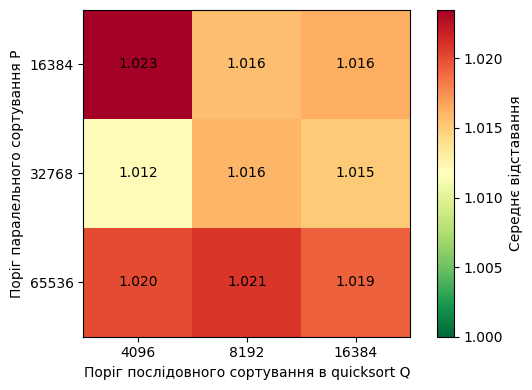

In [5]:
# 4. Теплокарта: середнє відставання по всіх графах для кожної пари (P, Q)
grid = summary["середнє_відставання"].unstack("qsort_cutoff").sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid.values, cmap="RdYlGn_r", vmin=1.0)
ax.set_xticks(range(len(grid.columns)), [str(c) for c in grid.columns])
ax.set_yticks(range(len(grid.index)), [str(i) for i in grid.index])
ax.set_xlabel("Поріг послідовного сортування в quicksort Q")
ax.set_ylabel("Поріг паралельного сортування P")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center", fontsize=10)
fig.colorbar(im, ax=ax, label="Середнє відставання")
fig.tight_layout()
fig.savefig(RESULTS + "fk_par_qsort.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
display(df[(df["graph"] == "C7") & (df["psort_cutoff"] == 16384) & (df["qsort_cutoff"] == 4096)][["repeat", "total_ms"]])

,repeat,total_ms
1152,1,2841.6409
1153,2,3599.1322
1154,3,3564.3713
1155,4,3597.5509
1156,5,3218.1926
1157,6,2888.3101
1158,7,2888.7224
